# Teacher results

In [1]:
import base64
import sys
import zlib
from pathlib import Path

import grid2op
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, Normalize

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))

from visualization.utils import GridPlottingArgs, visualize_grid

# ── Paths ──
TEACHER_EPISODES = ROOT / "results/teacher/aggregated/episodes_case36.csv"
TEACHER_EXPERIENCE = ROOT / "results/teacher/aggregated/experience_case36.csv"
ALL_CHRONICS = ROOT / "results/imitation/2026_10_12_imitation_case36_k208/summary/episodes.csv"

# ── Constants ──
MONTHS = ["january", "february", "march", "april", "may", "june",
          "july", "august", "september", "october", "november", "december"]
MONTH_LABELS = [m[:3].capitalize() for m in MONTHS]
STATUSES = ["complete", "never run", "truncated"]

# ── Palette ──
COLORS = {"complete": "#2a78d6", "never run": "#1baf7a", "truncated": "#eb6834"}
SURFACE, INK, INK_MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
CMAP = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])


def style(ax: plt.Axes) -> None:
    ax.set_facecolor(SURFACE)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(colors=INK_MUTED, length=0)
    ax.yaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)

/home/adrian/.conda/envs/L2RPN/lib/python3.10/site-packages/grid2op/MakeEnv/Make.py:13: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/home/adrian/.conda/envs/L2RPN/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-15 14:06:34,355	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.
2026-10-15 14:06:38,511	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


In [2]:
env = grid2op.make("l2rpn_wcci_2020_train")

teacher = pd.read_csv(TEACHER_EPISODES)
chronics = pd.read_csv(ALL_CHRONICS)[["chronic"]]
experience = pd.read_csv(TEACHER_EXPERIENCE)

print(f"{len(teacher)} teacher episodes, {len(experience):,} experience rows, "
      f"{len(experience['best_action'].unique())} unique actions")

2538 teacher episodes, 14,898 experience rows, 4773 unique actions


# Chronic coverage

status,complete,never run,truncated,total
month,,,,
january,160,20,35,215
february,167,10,39,216
march,177,1,37,215
april,214,0,0,214
may,214,0,0,214
june,219,0,0,219
july,210,0,0,210
august,218,0,0,218
september,219,0,0,219


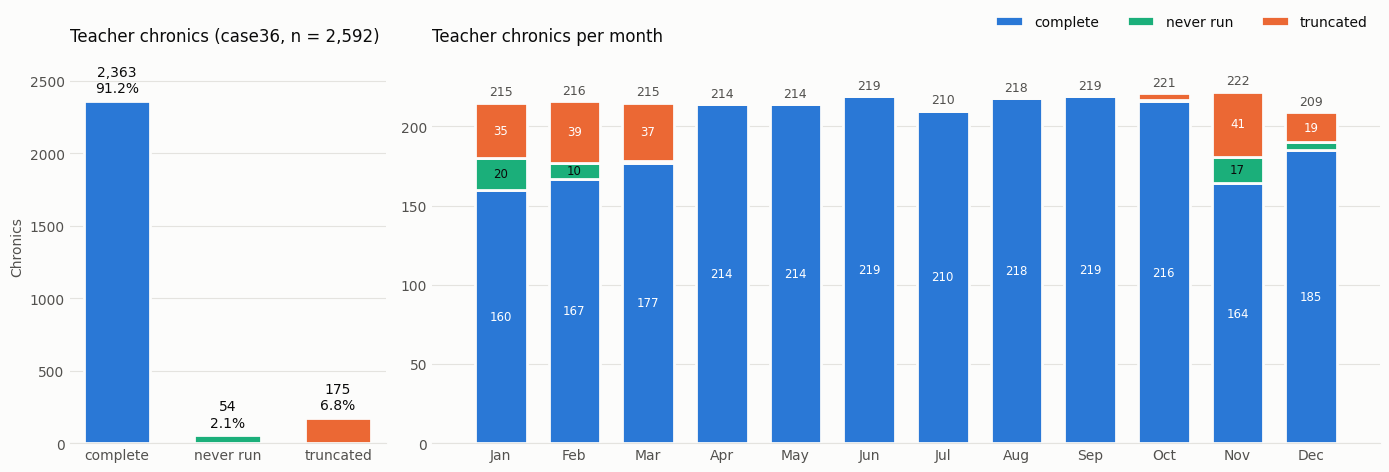

In [3]:
df = chronics.merge(teacher[["chronic", "truncated"]], on="chronic", how="left")
df["status"] = "complete"
df.loc[df["truncated"].isna(), "status"] = "never run"
df.loc[df["truncated"] == True, "status"] = "truncated"  # noqa: E712
df["month"] = pd.Categorical(
    df["chronic"].str.split("_").str[1], categories=MONTHS, ordered=True)

totals = df["status"].value_counts().reindex(STATUSES, fill_value=0)
by_month = (df.groupby(["month", "status"], observed=False)
            .size().unstack().reindex(columns=STATUSES, fill_value=0))
display(by_month.assign(total=by_month.sum(axis=1)))

fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(14, 4.8),
    gridspec_kw={"width_ratios": [1, 3]}, facecolor=SURFACE)

# Overall
bars = ax1.bar(STATUSES, totals.values, width=0.6,
               color=[COLORS[s] for s in STATUSES], edgecolor=SURFACE, linewidth=2)
for bar, n in zip(bars, totals.values):
    ax1.annotate(f"{n:,}\n{n / totals.sum():.1%}",
                 (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                 xytext=(0, 4), textcoords="offset points",
                 ha="center", va="bottom", color=INK, fontsize=10)
ax1.set_title(f"Teacher chronics (case36, n = {totals.sum():,})",
              loc="left", color=INK, fontsize=12)
ax1.set_ylabel("Chronics", color=INK_MUTED)
ax1.set_ylim(0, totals.max() * 1.15)
style(ax1)

# Per month, stacked
x = range(len(MONTHS))
bottom = pd.Series(0, index=by_month.index)
for status in STATUSES:
    values = by_month[status]
    segs = ax2.bar(x, values, bottom=bottom, width=0.7,
                   color=COLORS[status], label=status,
                   edgecolor=SURFACE, linewidth=2)
    for seg, n in zip(segs, values):
        if n >= 8:
            text_color = "white" if status != "never run" else INK
            ax2.text(seg.get_x() + seg.get_width() / 2,
                     seg.get_y() + seg.get_height() / 2, str(n),
                     ha="center", va="center", color=text_color, fontsize=8.5)
    bottom += values
for xi, total in zip(x, bottom):
    ax2.annotate(str(total), (xi, total), xytext=(0, 3),
                 textcoords="offset points",
                 ha="center", va="bottom", color=INK_MUTED, fontsize=9)
ax2.set_xticks(list(x), MONTH_LABELS)
ax2.set_ylim(0, bottom.max() * 1.12)
ax2.set_title("Teacher chronics per month", loc="left", color=INK, fontsize=12)
ax2.legend(frameon=False, ncols=3, loc="upper right",
           bbox_to_anchor=(1, 1.12), labelcolor=INK)
style(ax2)

plt.tight_layout()
plt.show()

# Action frequency distribution

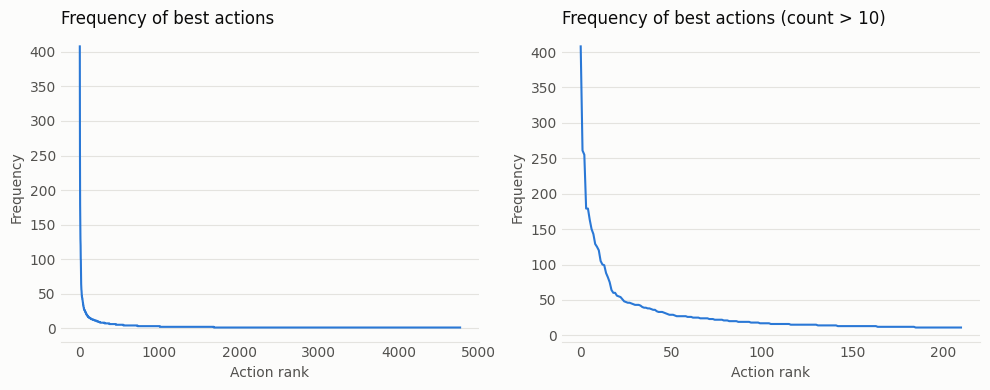

In [4]:
counts = experience["best_action"].value_counts()
ys = counts.values
xs = np.arange(len(ys))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), facecolor=SURFACE)

ax1.plot(xs, ys, color=COLORS["complete"])
ax1.set_title("Frequency of best actions", loc="left", color=INK, fontsize=12)
ax1.set_xlabel("Action rank", color=INK_MUTED)
ax1.set_ylabel("Frequency", color=INK_MUTED)
style(ax1)

ys_filtered = counts[counts > 10].values
xs_filtered = np.arange(len(ys_filtered))
ax2.plot(xs_filtered, ys_filtered, color=COLORS["complete"])
ax2.set_title("Frequency of best actions (count > 10)",
              loc="left", color=INK, fontsize=12)
ax2.set_xlabel("Action rank", color=INK_MUTED)
ax2.set_ylabel("Frequency", color=INK_MUTED)
style(ax2)

plt.tight_layout()
plt.show()

# Accumulated action frequency

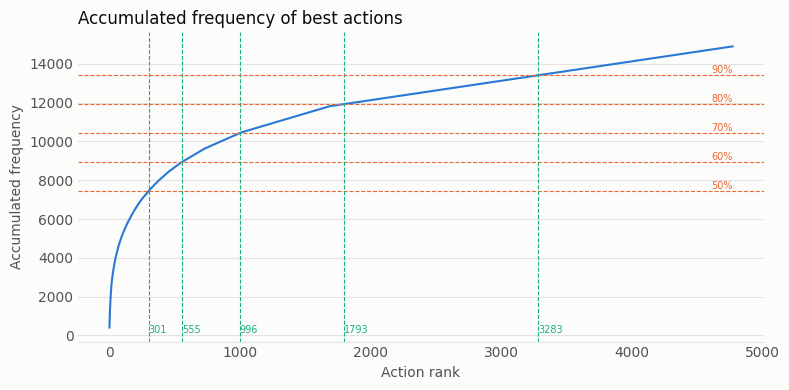

In [5]:
accumulated_counts = np.cumsum(ys)

fig, ax = plt.subplots(figsize=(8, 4), facecolor=SURFACE)
ax.plot(xs, accumulated_counts, color=COLORS["complete"])
for perc in [0.5, 0.6, 0.7, 0.8, 0.9]:
    threshold = perc * accumulated_counts[-1]
    idx = xs[np.searchsorted(accumulated_counts, threshold)]
    ax.axhline(y=threshold, color=COLORS["truncated"], linestyle="--", linewidth=0.8)
    ax.axvline(x=idx, color=COLORS["never run"], linestyle="--", linewidth=0.8)
    ax.text(xs[-1], threshold, f"{int(perc * 100)}%", color=COLORS["truncated"],
            fontsize=7, va="bottom", ha="right")
    ax.text(idx, 0, str(idx), color=COLORS["never run"],
            fontsize=7, va="bottom", ha="left")
ax.set_title("Accumulated frequency of best actions",
             loc="left", color=INK, fontsize=12)
ax.set_xlabel("Action rank", color=INK_MUTED)
ax.set_ylabel("Accumulated frequency", color=INK_MUTED)
style(ax)
plt.tight_layout()
plt.show()

# Top-k action space cutoff

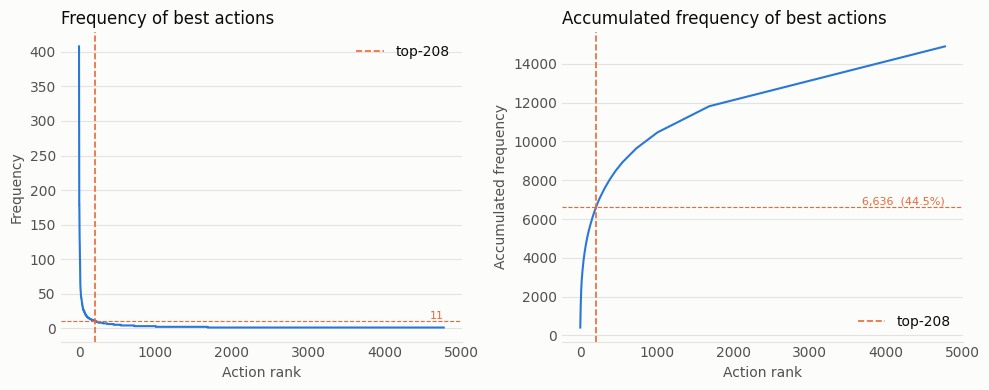

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), facecolor=SURFACE)

y_at_208 = ys[208]
ax1.plot(xs, ys, color=COLORS["complete"])
ax1.axvline(x=208, color=COLORS["truncated"], linestyle="--",
            linewidth=1.2, label="top-208")
ax1.axhline(y=y_at_208, color=COLORS["truncated"], linestyle="--", linewidth=0.8)
ax1.text(xs[-1], y_at_208, f"{y_at_208:,}", color=COLORS["truncated"],
         fontsize=8, va="bottom", ha="right")
ax1.set_title("Frequency of best actions", loc="left", color=INK, fontsize=12)
ax1.set_xlabel("Action rank", color=INK_MUTED)
ax1.set_ylabel("Frequency", color=INK_MUTED)
ax1.legend(frameon=False, labelcolor=INK)
style(ax1)

acc_at_208 = accumulated_counts[208]
pct_at_208 = acc_at_208 / accumulated_counts[-1]
ax2.plot(xs, accumulated_counts, color=COLORS["complete"])
ax2.axvline(x=208, color=COLORS["truncated"], linestyle="--",
            linewidth=1.2, label="top-208")
ax2.axhline(y=acc_at_208, color=COLORS["truncated"], linestyle="--", linewidth=0.8)
ax2.text(xs[-1], acc_at_208, f"{acc_at_208:,}  ({pct_at_208:.1%})",
         color=COLORS["truncated"], fontsize=8, va="bottom", ha="right")
ax2.set_title("Accumulated frequency of best actions",
              loc="left", color=INK, fontsize=12)
ax2.set_xlabel("Action rank", color=INK_MUTED)
ax2.set_ylabel("Accumulated frequency", color=INK_MUTED)
ax2.legend(frameon=False, labelcolor=INK)
style(ax2)

plt.tight_layout()
plt.show()

# Substation action distribution

In [7]:
GOOD_ONLY = True  # rows with rho improvement > 0.02 (the rows the k=208 space was ranked from)

topo_to_sub = np.repeat(np.arange(env.n_sub), env.sub_info)
possible_actions = pd.Series(2.0 ** (env.sub_info - 1), index=range(env.n_sub))


def action_substations(encoded: str) -> tuple[int, ...]:
    """Substations a Teacher action changes. Encoding: base64(zlib(set_topo_vect as int32))."""
    set_topo = np.frombuffer(
        zlib.decompress(base64.b64decode(encoded)), dtype=np.int32)
    return tuple(np.unique(topo_to_sub[set_topo != 0]).tolist())


exp = experience[experience["good"]] if GOOD_ONLY else experience
subs = exp["best_action"].map(action_substations)
assert (subs.map(len) == 1).all(), "expected unitary (single-substation) actions"
picks = subs.str[0].value_counts().reindex(range(env.n_sub), fill_value=0)

table = pd.DataFrame({
    "picks": picks,
    "share": picks / picks.sum(),
    "possible_actions": possible_actions.astype(int),
    "normalized_picks": picks / possible_actions,
    "distinct_actions": exp.groupby(subs.str[0])["best_action"].nunique()
                           .reindex(range(env.n_sub), fill_value=0),
})
table.index.name = "substation"
display(table[table["picks"] > 0].sort_values("picks", ascending=False)
        .style.format({"share": "{:.1%}", "normalized_picks": "{:.4f}"}))

,picks,share,possible_actions,normalized_picks,distinct_actions
substation,,,,,
16,5951,48.9%,65536,0.0908,3556
23,1550,12.7%,512,3.0273,279
4,494,4.1%,32,15.4375,21
21,452,3.7%,128,3.5312,75
9,398,3.3%,64,6.2188,52
35,355,2.9%,64,5.5469,15
26,327,2.7%,256,1.2773,97
1,305,2.5%,32,9.5312,4
33,292,2.4%,64,4.5625,56


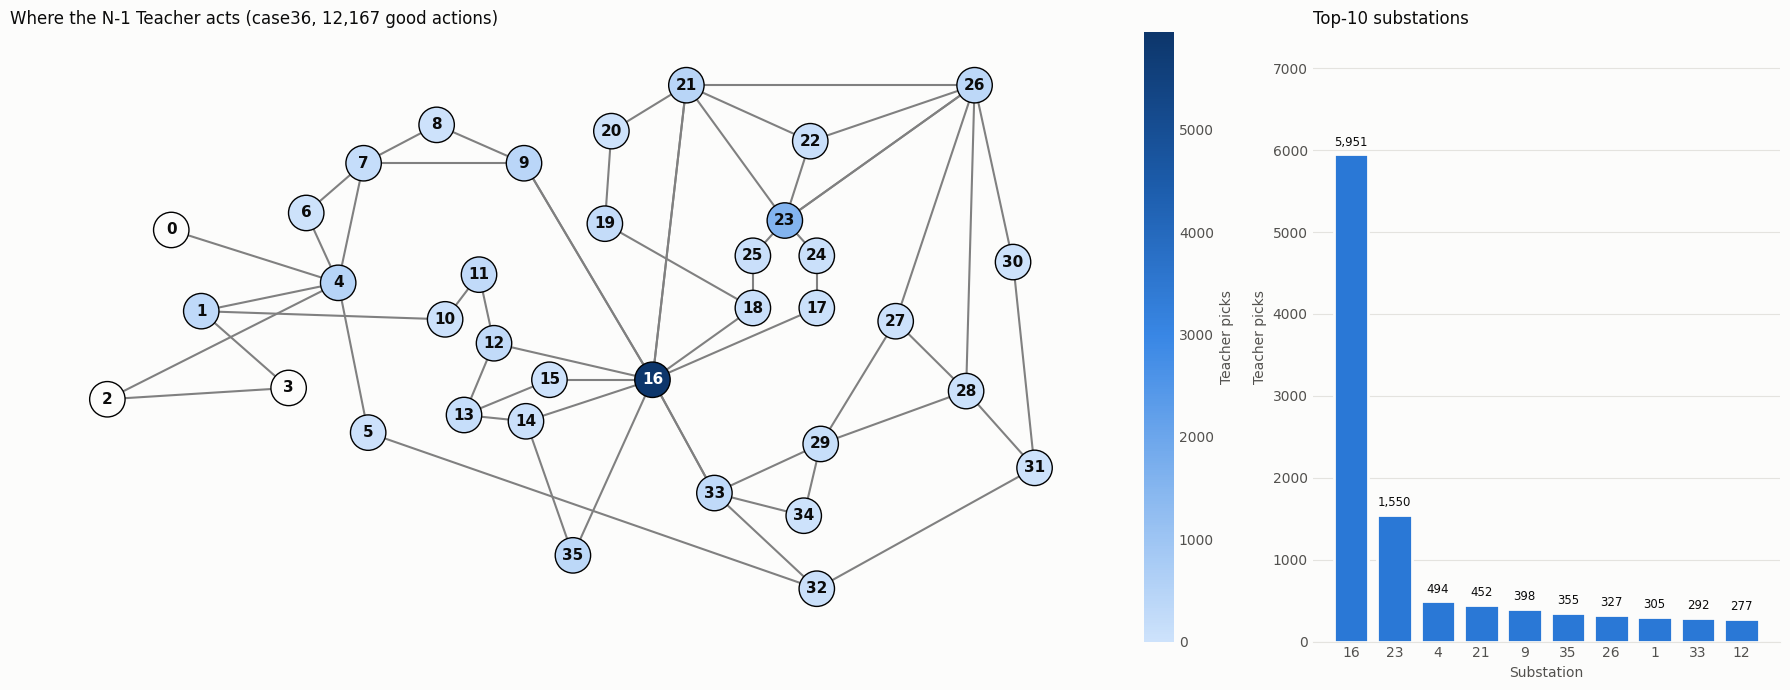

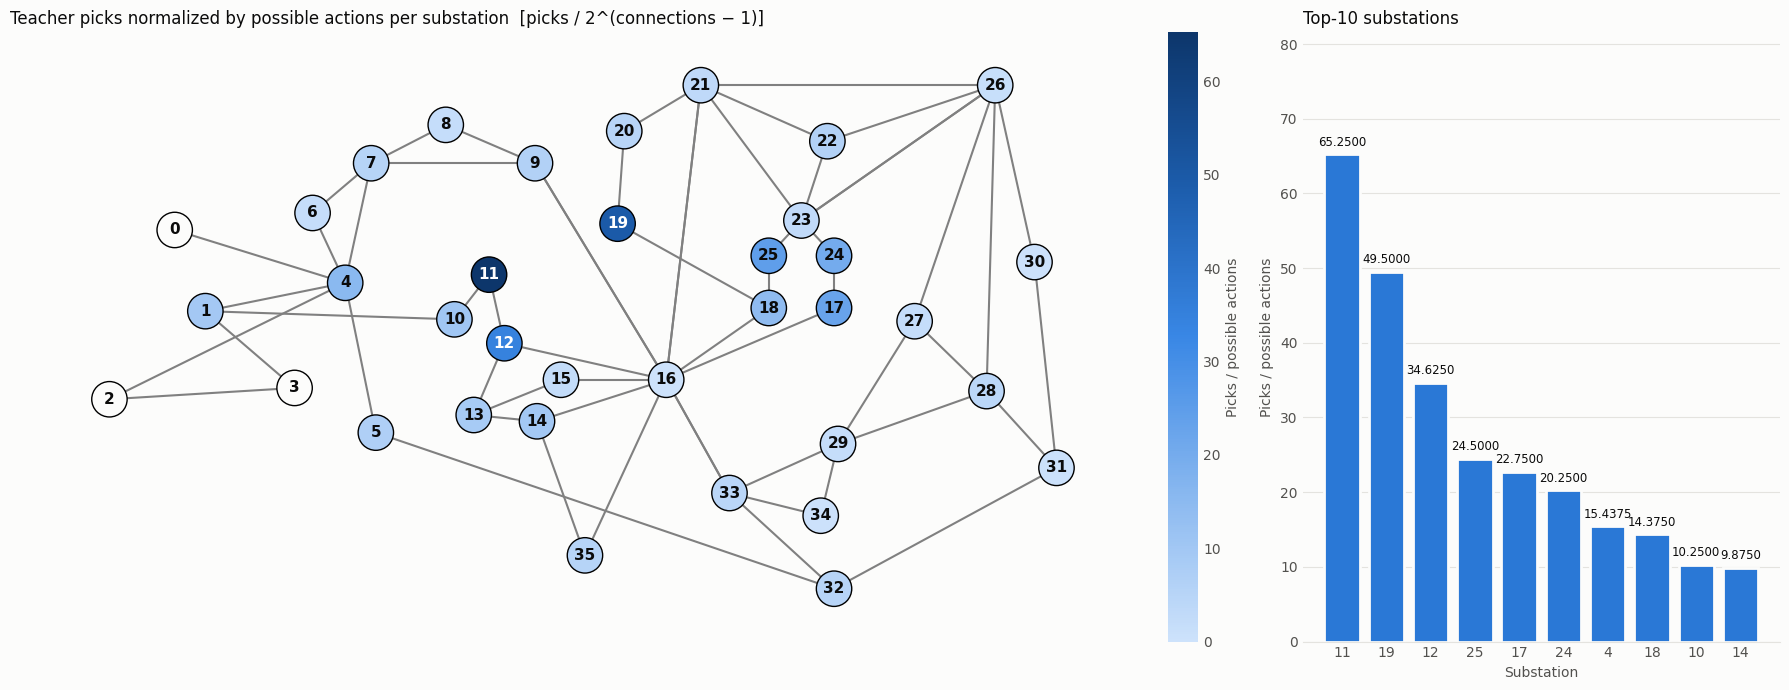

In [8]:
NO_PICKS = SURFACE


def _text_ink(r: float, g: float, b: float) -> str:
    return "white" if 0.2126 * r + 0.7152 * g + 0.0722 * b < 0.5 else INK


def draw_substation_panels(values: pd.Series, title: str,
                           ylabel: str, bar_label_fmt: str) -> None:
    top10 = values.sort_values(ascending=False).head(10)
    norm = Normalize(vmin=0, vmax=values.max())
    node_colors = [CMAP(norm(values[i])) if picks[i] > 0 else NO_PICKS
                   for i in range(env.n_sub)]

    fig, (ax_grid, ax_bar) = plt.subplots(
        1, 2, figsize=(18, 7),
        gridspec_kw={"width_ratios": [2.5, 1]}, facecolor=SURFACE)

    visualize_grid(GridPlottingArgs(
        env=env, node_colors=node_colors, node_size=650, font_size=11), ax=ax_grid)
    ax_grid.set_facecolor(SURFACE)
    fig.patch.set_facecolor(SURFACE)

    for text in ax_grid.texts:
        if text.get_text().isdigit():
            sub_id = int(text.get_text())
            r, g, b, _ = (CMAP(norm(values[sub_id])) if picks[sub_id] > 0
                           else (*[c / 255 for c in (0xfc, 0xfc, 0xfb)], 1))
            text.set_color(_text_ink(r, g, b))

    sm = plt.cm.ScalarMappable(norm=norm, cmap=CMAP)
    cbar = fig.colorbar(sm, ax=ax_grid, fraction=0.03, pad=0.01)
    cbar.set_label(ylabel, color=INK_MUTED)
    cbar.outline.set_visible(False)
    cbar.ax.tick_params(colors=INK_MUTED, length=0)
    ax_grid.set_title(title, loc="left", color=INK, fontsize=12)

    bars = ax_bar.bar([str(s) for s in top10.index], top10.values,
                      color=COLORS["complete"], edgecolor=SURFACE, linewidth=2)
    for bar, (sub_id, val) in zip(bars, top10.items()):
        ax_bar.annotate(bar_label_fmt.format(val=val),
                        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                        xytext=(0, 4), textcoords="offset points",
                        ha="center", va="bottom", color=INK, fontsize=8.5)
    ax_bar.set_title("Top-10 substations", loc="left", color=INK, fontsize=12)
    ax_bar.set_xlabel("Substation", color=INK_MUTED)
    ax_bar.set_ylabel(ylabel, color=INK_MUTED)
    ax_bar.set_ylim(0, top10.max() * 1.25)
    style(ax_bar)

    plt.tight_layout()
    plt.show()


# Raw picks
draw_substation_panels(
    picks.astype(float),
    title=f"Where the N-1 Teacher acts (case36, "
          f"{picks.sum():,} {'good ' if GOOD_ONLY else ''}actions)",
    ylabel="Teacher picks",
    bar_label_fmt="{val:,.0f}",
)

# Normalized: picks / 2^(connections − 1)
draw_substation_panels(
    picks / possible_actions,
    title="Teacher picks normalized by possible actions per substation  "
          "[picks / 2^(connections − 1)]",
    ylabel="Picks / possible actions",
    bar_label_fmt="{val:.4f}",
)